In [1]:
import torch
import matplotlib.pyplot as plt
import torch.nn.functional as F

In [2]:
# y = 3 * x + 2

In [3]:
# when we know Y, e.g., 7, it is clear that X this will be the value that yields that result

In [4]:
target = torch.tensor(7)

In [5]:
def f1(x):
    return 3 * x + 2

In [6]:
f1(1), f1(2)

(5, 8)

In [7]:
f1(1.5), f1(1.7)

(6.5, 7.1)

In [8]:
f1(1.6)

6.800000000000001

In [9]:
f1(1.666)

6.997999999999999

In [10]:
# okay, so it’s clear that it’ll be ~1.666 or something around that

In [11]:
seed = 3407
torch.manual_seed(seed)
xs = torch.randn(1, requires_grad=True)

In [12]:
f1(xs)

tensor([5.2912], grad_fn=<AddBackward0>)

In [13]:
def loss_fn(y, x):
    return y - x

In [14]:
loss = loss_fn(target, f1(xs))

In [15]:
loss

tensor([1.7088], grad_fn=<SubBackward0>)

In [16]:
xs.grad = None

In [17]:
loss.backward()

In [18]:
xs.grad

tensor([-3.])

In [19]:
# okay, so I have a GRAD vector that I can use to calculate new parameters

In [20]:
# forward, backward, update

In [21]:
loss = loss_fn(target, f1(xs))
print(loss)
xs.grad = None
loss.backward()
xs.data -= 0.01 * xs.grad

tensor([1.7088], grad_fn=<SubBackward0>)


In [22]:
xs

tensor([1.1271], requires_grad=True)

In [23]:
f1(xs)

tensor([5.3812], grad_fn=<AddBackward0>)

In [24]:
# take more steps

In [25]:
seed = 3407
torch.manual_seed(seed)
xs = torch.randn(1, requires_grad=True)

In [26]:
def loss_fn(y, x):
    return y - x

In [27]:
arr = [] # for xs.data[0].item()

In [28]:
for step in range(30):
    loss = loss_fn(target, f1(xs))
    print(step, loss.item(), xs.data[0].item(), xs.grad)
    xs.grad = None
    loss.backward()
    arr.append(xs.data[0].item())
    xs.data -= 0.01 * xs.grad

0 1.7088375091552734 1.097054123878479 None
1 1.618837833404541 1.1270540952682495 tensor([-3.])
2 1.5288376808166504 1.15705406665802 tensor([-3.])
3 1.438838005065918 1.1870540380477905 tensor([-3.])
4 1.3488378524780273 1.217054009437561 tensor([-3.])
5 1.258838176727295 1.2470539808273315 tensor([-3.])
6 1.1688380241394043 1.277053952217102 tensor([-3.])
7 1.0788383483886719 1.3070539236068726 tensor([-3.])
8 0.9888381958007812 1.337053894996643 tensor([-3.])
9 0.8988385200500488 1.3670538663864136 tensor([-3.])
10 0.8088383674621582 1.397053837776184 tensor([-3.])
11 0.7188386917114258 1.4270538091659546 tensor([-3.])
12 0.6288385391235352 1.457053780555725 tensor([-3.])
13 0.5388388633728027 1.4870537519454956 tensor([-3.])
14 0.4488387107849121 1.5170537233352661 tensor([-3.])
15 0.3588390350341797 1.5470536947250366 tensor([-3.])
16 0.26883888244628906 1.5770536661148071 tensor([-3.])
17 0.17883920669555664 1.6070536375045776 tensor([-3.])
18 0.08883905410766602 1.6370536088943

In [29]:
# okay, so I’ve reset the counter here, since it dropped to -0.9911
# The counter has gone below 0. Where is the theoretical minimum of the function...?! 

In [30]:
f1(1.6370536)

6.9111608

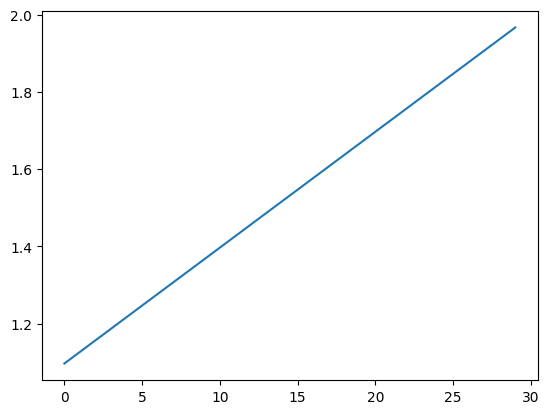

In [31]:
plt.plot(arr)

In [32]:
# How does MSE measure the error and teach the parameter in `xs` the correct value?

In [33]:
def loss_fn(y, x):
    return (y - x) ** 2

In [34]:
seed = 3407
torch.manual_seed(seed)
xs = torch.randn(1, requires_grad=True)

In [35]:
xs, f1(xs)

(tensor([1.0971], requires_grad=True),
 tensor([5.2912], grad_fn=<AddBackward0>))

In [36]:
arr_loss = []
arr_grad = []

In [37]:
for step in range(50):
    loss = loss_fn(target, f1(xs))
    #print(loss)
    xs.grad = None
    loss.backward()
    print(xs.grad.item(), loss.item())
    arr_loss.append(loss.item())
    arr_grad.append(xs.grad.item())
    xs.data -= 0.01 * xs.grad

-10.25302505493164 2.920125722885132
-8.407482147216797 1.9634932279586792
-6.894132614135742 1.3202518224716187
-5.653189659118652 0.8877375721931458
-4.635615348815918 0.5969147086143494
-3.801203727722168 0.4013652801513672
-3.1169872283935547 0.2698780298233032
-2.555929183959961 0.18146593868732452
-2.09586238861084 0.1220177561044693
-1.7186050415039062 0.08204453438520432
-1.409256935119629 0.055166807025671005
-1.1555900573730469 0.0370941199362278
-0.9475851058959961 0.024942154064774513
-0.7770195007324219 0.016771091148257256
-0.6371555328369141 0.011276866309344769
-0.5224685668945312 0.007582594640552998
-0.4284238815307617 0.005098528228700161
-0.35130786895751953 0.0034282561391592026
-0.2880706787109375 0.0023051309399306774
-0.2362203598022461 0.0015500016743317246
-0.19369983673095703 0.0010422118939459324
-0.15883255004882812 0.0007007716340012848
-0.13024234771728516 0.0004711963701993227
-0.1067962646484375 0.0003168178373016417
-0.08757305145263672 0.0002130288776

In [38]:
f1(xs)

tensor([6.9999], grad_fn=<AddBackward0>)

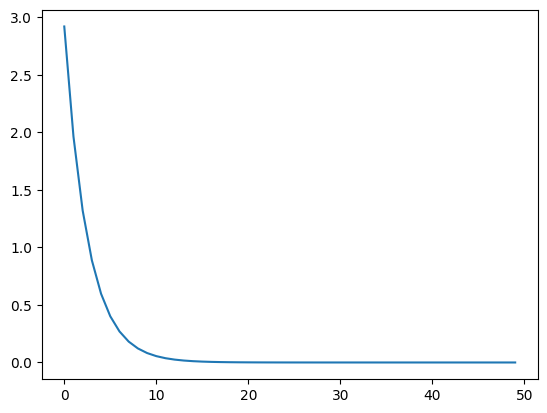

In [39]:
plt.plot(arr_loss)

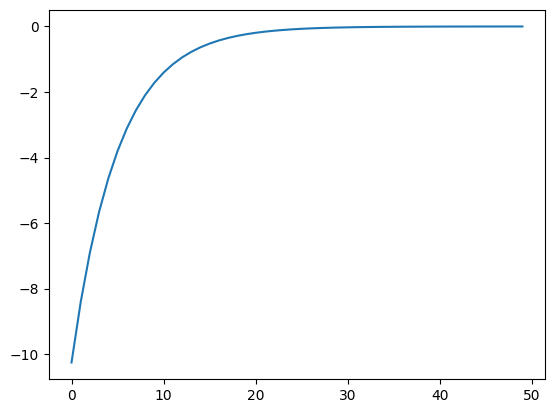

In [40]:
plt.plot(arr_grad)

In [41]:
xs.item()

1.666638731956482

In [42]:
f1(xs)

tensor([6.9999], grad_fn=<AddBackward0>)

In [43]:
ret = target.item()-f1(xs).item()
print(f"{ret:.7f}")

0.0000839


In [44]:
# https://gist.github.com/yang-zhang/217dcc6ae9171d7a46ce42e215c1fee0

In [45]:
# https://github.com/KarolDuracz/Machine-Learning/tree/main/7%20-%20micrograd%20exercises/3%20-%20exercise%20number%207-3

In [46]:
# https://github.com/KarolDuracz/Machine-Learning/tree/main/7%20-%20micrograd%20exercises/3%20-%20exercise%20number%207-3/makemore_exercises

In [47]:
# ( Softmax ) -> Cross Entropy

In [48]:
seed = 3407
torch.manual_seed(seed)
xs = torch.randn(1, requires_grad=True)

In [49]:
xs

tensor([1.0971], requires_grad=True)

In [50]:
F.softmax(xs, dim=0)

tensor([1.], grad_fn=<SoftmaxBackward0>)

In [51]:
target

tensor(7)

In [52]:
F.cross_entropy(xs, target)

IndexError: Target 7 is out of bounds.

In [53]:
# F.cross_entropy picks index from vector. I need more values to take 1, 2, etc as index to calc entropy

In [54]:
seed = 3407
torch.manual_seed(seed)
xs = torch.randn(10, requires_grad=True)

In [55]:
xs

tensor([ 1.0971,  0.5328, -0.3311, -0.4458,  0.6679,  0.7001, -0.8284,  2.1086,
        -1.0221, -1.3357], requires_grad=True)

In [56]:
F.softmax(xs, dim=0)

tensor([0.1551, 0.0882, 0.0372, 0.0331, 0.1009, 0.1043, 0.0226, 0.4264, 0.0186,
        0.0136], grad_fn=<SoftmaxBackward0>)

In [57]:
F.cross_entropy(xs, target)

tensor(0.8524, grad_fn=<NllLossBackward0>)

In [58]:
# calculate it by hand

In [59]:
def _softmax(x):
    return x.exp() / x.exp().sum()

In [60]:
_softmax(xs)

tensor([0.1551, 0.0882, 0.0372, 0.0331, 0.1009, 0.1043, 0.0226, 0.4264, 0.0186,
        0.0136], grad_fn=<DivBackward0>)

In [61]:
F.softmax(xs, dim=0) == _softmax(xs)

tensor([ True,  True, False, False,  True, False, False, False,  True, False])

In [62]:
F.softmax(xs, dim=0).sum(), _softmax(xs).sum()

(tensor(1., grad_fn=<SumBackward0>), tensor(1., grad_fn=<SumBackward0>))

In [63]:
# There are some differences, but...

In [64]:
F.softmax(xs, dim=0) - _softmax(xs)

tensor([ 0.0000e+00,  0.0000e+00,  3.7253e-09,  3.7253e-09,  0.0000e+00,
         7.4506e-09,  1.8626e-09,  2.9802e-08,  0.0000e+00, -9.3132e-10],
       grad_fn=<SubBackward0>)

In [65]:
(F.softmax(xs, dim=0) - _softmax(xs))[2].item()

3.725290298461914e-09

In [66]:
ret = (F.softmax(xs, dim=0) - _softmax(xs))[2].item()
print(f"{ret:.10f}")

0.0000000037


In [67]:
# ... with a precision of ~10 decimal places

In [68]:
# ok, so... _softmax yields more or less the same result
# This isn't the complete formula—you might need something like `x.exp() / (x.exp().sum(-1)).unsqueeze(-1)`—but this is sufficient for now.

In [69]:
# CE picks index, for 7 it is..

In [70]:
_softmax(xs)[7]

tensor(0.4264, grad_fn=<SelectBackward0>)

In [71]:
_softmax(xs)[7].log()

tensor(-0.8524, grad_fn=<LogBackward0>)

In [72]:
_softmax(xs)[7].log().neg()

tensor(0.8524, grad_fn=<NegBackward0>)

In [73]:
# 

In [74]:
F.cross_entropy(xs, target)

tensor(0.8524, grad_fn=<NllLossBackward0>)

In [75]:
# again, slight differences but it's fine here

In [76]:
_softmax(xs)[7].log().neg().item(), F.cross_entropy(xs, target).item()

(0.8523970246315002, 0.8523969650268555)

In [77]:
ret = _softmax(xs)[7].log().neg().item() - F.cross_entropy(xs, target).item()
print(f"{ret:.10f}")

0.0000000596


In [78]:
# these are very small differences

In [79]:
# So 0.8524 is a loss

In [80]:
seed = 3407
torch.manual_seed(seed)
xs = torch.randn(10, requires_grad=True)

In [81]:
xs

tensor([ 1.0971,  0.5328, -0.3311, -0.4458,  0.6679,  0.7001, -0.8284,  2.1086,
        -1.0221, -1.3357], requires_grad=True)

In [82]:
arr_loss = []
arr_grad = []
xs_clone = xs.clone()

In [83]:
for step in range(50):
    loss = F.cross_entropy(f1(xs), target)
    print(loss)
    xs.grad = None
    loss.backward()
    #print(xs.grad.item(), loss.item())
    #arr_loss.append(loss.item())
    #arr_grad.append(xs.grad.item())
    xs.data -= 0.1 * xs.grad

tensor(0.0827, grad_fn=<NllLossBackward0>)
tensor(0.0753, grad_fn=<NllLossBackward0>)
tensor(0.0691, grad_fn=<NllLossBackward0>)
tensor(0.0638, grad_fn=<NllLossBackward0>)
tensor(0.0593, grad_fn=<NllLossBackward0>)
tensor(0.0554, grad_fn=<NllLossBackward0>)
tensor(0.0520, grad_fn=<NllLossBackward0>)
tensor(0.0490, grad_fn=<NllLossBackward0>)
tensor(0.0463, grad_fn=<NllLossBackward0>)
tensor(0.0439, grad_fn=<NllLossBackward0>)
tensor(0.0417, grad_fn=<NllLossBackward0>)
tensor(0.0398, grad_fn=<NllLossBackward0>)
tensor(0.0380, grad_fn=<NllLossBackward0>)
tensor(0.0363, grad_fn=<NllLossBackward0>)
tensor(0.0349, grad_fn=<NllLossBackward0>)
tensor(0.0335, grad_fn=<NllLossBackward0>)
tensor(0.0322, grad_fn=<NllLossBackward0>)
tensor(0.0310, grad_fn=<NllLossBackward0>)
tensor(0.0299, grad_fn=<NllLossBackward0>)
tensor(0.0289, grad_fn=<NllLossBackward0>)
tensor(0.0280, grad_fn=<NllLossBackward0>)
tensor(0.0271, grad_fn=<NllLossBackward0>)
tensor(0.0263, grad_fn=<NllLossBackward0>)
tensor(0.02

In [84]:
xs.data

tensor([ 0.8722,  0.4787, -0.3355, -0.4489,  0.5897,  0.6149, -0.8294,  2.5601,
        -1.0227, -1.3359])

In [85]:
f1(xs)

tensor([ 4.6167,  3.4361,  0.9936,  0.6534,  3.7691,  3.8448, -0.4881,  9.6802,
        -1.0681, -2.0078], grad_fn=<AddBackward0>)

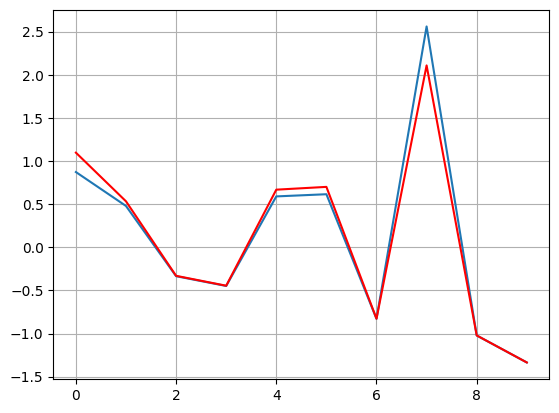

In [86]:
plt.plot(xs.detach().numpy())
plt.plot(xs_clone.detach().numpy(), color='red')
plt.grid()

In [87]:
pred = torch.multinomial(F.softmax(f1(xs), dim=0), num_samples=100, replacement=True)

In [88]:
pred.sort().values

tensor([0, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7,
        7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7,
        7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7,
        7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7,
        7, 7, 7, 7])

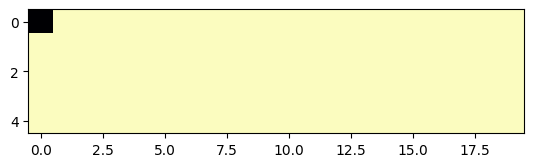

In [89]:
plt.imshow(pred.sort().values.view(5,-1), cmap='magma')

In [90]:
# For this setup, with a seed of 3407, the state after weight initialization is practically the same as it is after training. 
# We need to remove the seed from the generator to produce random values. doing so yields different results, and you can then see 
# the difference between `xs` and `xs_clone` on the plot. `multinomial` is really effective when it comes to sampling from an 
# entire probability distribution.
# 
# seed = 3407                                      <<<< remove this
# torch.manual_seed(seed)                          <<<< remove this
# xs = torch.randn(10, requires_grad=True)